# Early results: three local Ollama models

This notebook reads the collected 75-puzzle pilot and creates descriptive summaries and, only when both outcome classes exist, preliminary logistic regression and decision tree models.

**Protocol:** identical FEN-only prompt, fresh request for each solver turn, no tools, Qwen thinking disabled, temperature 0, 128 output tokens. Scores require completing the official solver line. Alternatives are not engine-adjudicated. The same five-puzzle smoke subset is included because no protocol changes followed inspection.

Models differ in size and quantization. This study measures these local deployments under this direct-answer protocol, not general LLM chess ability. A fixed puzzle-level holdout prevents the same puzzle appearing in both training and testing. Sparse-outcome inference is explicitly deferred.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if root.name == 'code': root = root.parent
sys.path.insert(0, str(root / 'code'))
from analyze_early_results import main
report = main()


             attempts  solved  solve_rate  mean_seconds
llm_name                                               
gemma3:4b          75       0         0.0      1.369627
llama3.1:8b        75       0         0.0      1.356947
qwen3:8b           75       0         0.0      1.403093

Failure categories:
failure_type  illegal_move  legal_incorrect  unparseable
llm_name                                                
gemma3:4b                3                2           70
llama3.1:8b             31                0           44
qwen3:8b                 7                0           68

{
  "planned_attempts": 225,
  "recorded_attempts": 225,
  "scored_attempts": 225,
  "infrastructure_errors": 0,
  "distinct_puzzles": 75,
  "notes": [
    "Preliminary, balanced rating-stratum sample; not population-weighted.",
    "Official-line exact matching; legal alternatives have not been engine-adjudicated.",
    "Direct-answer FEN-only protocol; Qwen thinking disabled; 128-token output cap.",
    "Mod

,llm_name,attempts,solved,solve_rate,mean_seconds
0,gemma3:4b,75,0,0.0,1.369627
1,llama3.1:8b,75,0,0.0,1.356947
2,qwen3:8b,75,0,0.0,1.403093


,llm_name,illegal_move,legal_incorrect,unparseable
0,gemma3:4b,3,2,70
1,llama3.1:8b,31,0,44
2,qwen3:8b,7,0,68


,llm_name,rating_stratum,n,solved,solve_rate
0,gemma3:4b,high,25,0,0.0
1,gemma3:4b,low,25,0,0.0
2,gemma3:4b,middle,25,0,0.0
3,llama3.1:8b,high,25,0,0.0
4,llama3.1:8b,low,25,0,0.0
5,llama3.1:8b,middle,25,0,0.0
6,qwen3:8b,high,25,0,0.0
7,qwen3:8b,low,25,0,0.0
8,qwen3:8b,middle,25,0,0.0


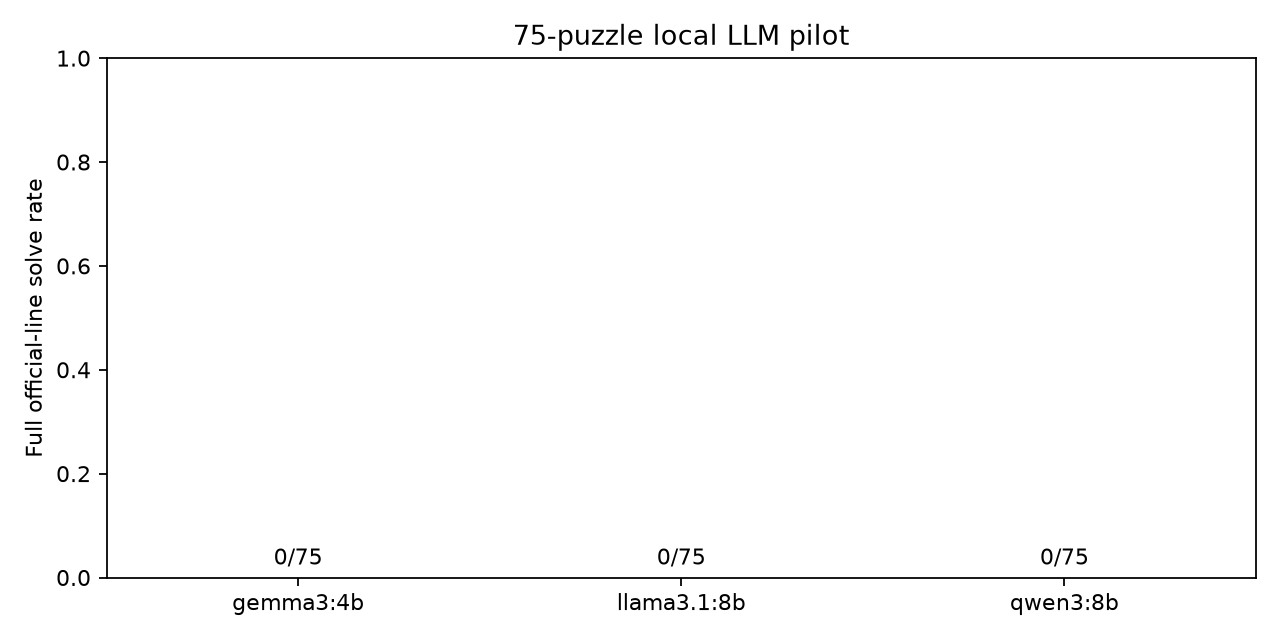

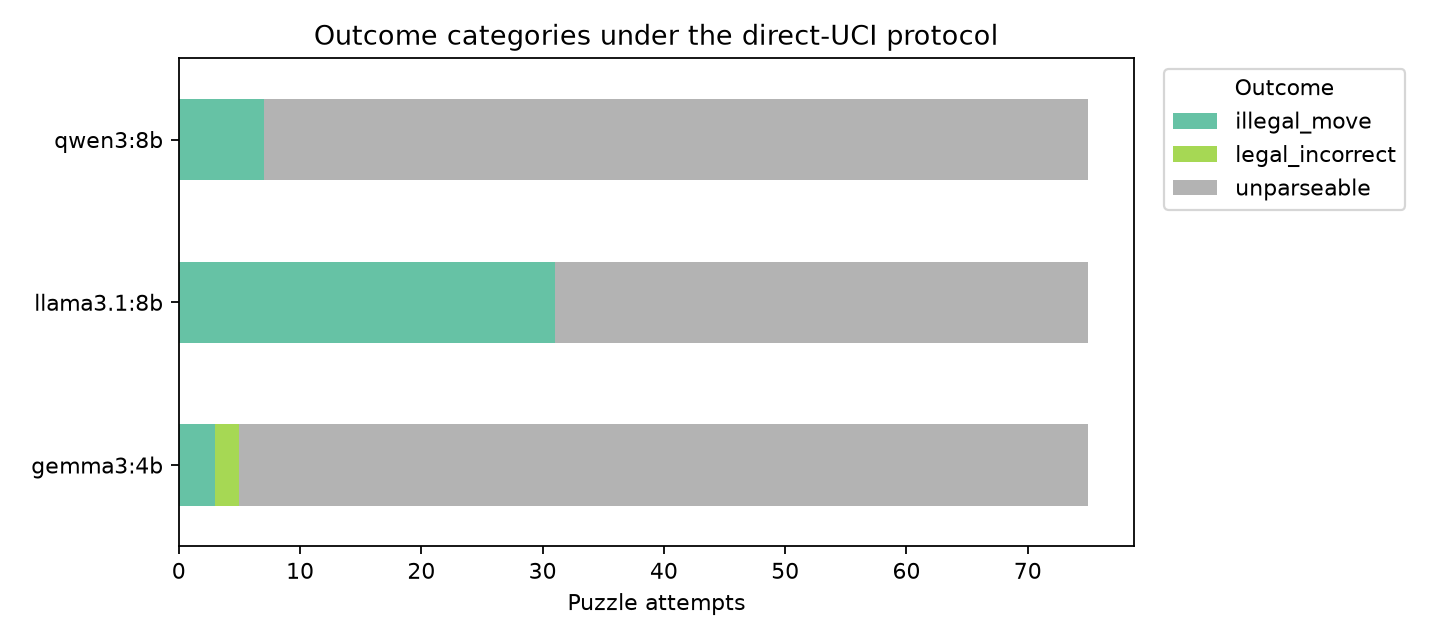

Not fitted: outcome has fewer than two classes. Collect a revised, separately versioned pilot or more observations.


In [2]:
import pandas as pd
from IPython.display import display, Image
analysis = root / 'data/analysis/local_pilot_v2'
display(pd.read_csv(analysis / 'solve_rates.csv'))
display(pd.read_csv(analysis / 'failure_counts.csv'))
display(pd.read_csv(analysis / 'solve_rates_by_rating.csv'))
display(Image(filename=str(root / 'figures/local_pilot_v2/solve_rates.png')))
display(Image(filename=str(root / 'figures/local_pilot_v2/failure_breakdown.png')))
if 'metrics' in report:
    display(pd.read_csv(analysis / 'model_metrics.csv'))
    display(Image(filename=str(root / 'figures/local_pilot_v2/decision_tree.png')))
else:
    print(report['model_status'])


## Interpretation and next steps

Inspect the failure breakdown before treating solve rates as chess-skill measurements: move notation and board interpretation are part of this protocol. A constant outcome cannot support binary classification or ROC-AUC. Do not replace outcomes with fabricated labels or change the definition of success after collection.

If success is too sparse, preserve this experiment and run a separately versioned pilot that tests an explicit board listing in addition to FEN and/or supplied legal move candidates. Keep puzzles and scoring comparable, document the assistance, and treat prompt development separately from later held-out evaluation. Main-study collection and planned XGBoost remain subsequent stages.

Reproduce collection: `python code/run_llm_puzzles.py --stage pilot` using the project environment and the unchanged model digests. Re-run this notebook to rebuild analysis. Data and raw logs live under `data/experiments/local_pilot_v2/`; data is excluded from Git by the existing project policy.